# Bitcoin-Volatilität: Datenbasis und explorative Analyse

In diesem ersten Notebook-Teil bauen wir eine reproduzierbare Datenbasis für
die Prognose der zukünftigen realisierten Bitcoin-Volatilität auf. Wir laden
BTC-USD, Fear & Greed, VIX, DXY und Nasdaq, richten die Zeitreihen ohne
Look-ahead Leakage aus, definieren die Zielvariable und untersuchen die
wichtigsten Muster.

**Primäres Ziel:** zukünftige realisierte Volatilität über sieben Tage.

**Noch nicht enthalten:** Walk-forward Backtesting und die Modelle Naive,
GARCH, XGBoost und Chronos-2. Diese bauen später auf der hier erzeugten
Modelling-Tabelle auf.

## Kurzfassung

Wir erstellen in diesem Notebook eine tägliche Modelling-Tabelle ab 2018.
Externe Variablen verschieben wir um einen Tag, wenn der genaue
Veröffentlichungszeitpunkt nicht sicher ist. Damit verwenden die Features am
Tag \(t\) nur Informationen, die zu diesem Zeitpunkt bereits bekannt sind.

Die konkreten Datenzeiträume, fehlenden Werte und EDA-Ergebnisse werden beim
Ausführen des Notebooks berechnet und direkt unter den jeweiligen Ausgaben
interpretiert.

## 1. Setup

### Erklärung

Wir bündeln alle veränderbaren Parameter in einer Zelle und setzen einen
zufälligen Seed. Für spätere PyTorch-Modelle wählen wir auf Apple Silicon
automatisch `mps`, sofern das installierte PyTorch und das System diesen
Backend unterstützen. Die Datenaufbereitung in diesem ersten Teil läuft
bewusst auf der CPU.

In [1]:
from importlib.metadata import PackageNotFoundError, version
from pathlib import Path
import platform
import random
import sys

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import yfinance as yf

# Keep all configuration visible and easy to change
RANDOM_SEED = 42
START_DATE = "2018-02-01"
END_DATE = (pd.Timestamp.today().normalize() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
FORECAST_HORIZON = 7

# Resolve paths whether Jupyter starts in the project root or notebooks folder
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Make random operations reproducible
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Use one consistent visual language throughout the notebook
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "figure.dpi": 110,
    }
)
VIRIDIS = plt.colormaps["viridis"]
COLORS = {
    "btc": VIRIDIS(0.12),
    "volatility": VIRIDIS(0.38),
    "fear_greed": VIRIDIS(0.58),
    "vix": VIRIDIS(0.72),
    "dxy": VIRIDIS(0.84),
    "nasdaq": VIRIDIS(0.96),
}

# Detect MPS without making PyTorch mandatory for basic data preparation
try:
    import torch

    TORCH_VERSION = torch.__version__
    DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
except ImportError:
    torch = None
    TORCH_VERSION = "nicht installiert"
    DEVICE = "cpu"


def installed_version(package_name):
    '''Return a package version for the reproducibility table.'''
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "nicht installiert"


# Show the environment instead of hiding setup assumptions
environment_table = pd.DataFrame(
    {
        "Komponente": [
            "Python",
            "Betriebssystem",
            "Prozessor",
            "PyTorch",
            "Gewähltes Gerät",
            "pandas",
            "yfinance",
        ],
        "Wert": [
            platform.python_version(),
            platform.platform(),
            platform.machine(),
            TORCH_VERSION,
            DEVICE,
            installed_version("pandas"),
            installed_version("yfinance"),
        ],
    }
)
display(environment_table)

,Komponente,Wert
0,Python,3.11.13
1,Betriebssystem,macOS-26.5.2-arm64-arm-64bit
2,Prozessor,arm64
3,PyTorch,2.13.0
4,Gewähltes Gerät,mps
5,pandas,3.0.3
6,yfinance,1.5.1


### Interpretation

Wir verwenden MPS nur für spätere PyTorch-Inferenz oder ein mögliches
Fine-Tuning. pandas, yfinance, GARCH und XGBoost bleiben auf der CPU. Dadurch
vermeiden wir unnötige Transfers zwischen CPU und GPU. Die Tabelle dokumentiert
die tatsächlich verwendete Umgebung für die Reproduzierbarkeit.

## 2. Daten laden

### Erklärung

Wir beziehen BTC-USD, VIX, DXY und Nasdaq über `yfinance`. Den Fear & Greed
Index laden wir über die öffentliche API von Alternative.me. Um wiederholte
Downloads zu vermeiden, speichern wir jede Rohzeitreihe lokal als CSV.

Verwendete Yahoo-Symbole:

| Inhalt | Symbol |
|---|---|
| Bitcoin in USD | `BTC-USD` |
| VIX | `^VIX` |
| US-Dollar-Index | `DX-Y.NYB` |
| Nasdaq Composite | `^IXIC` |

Der Endzeitpunkt von `yfinance.download()` ist exklusiv. Deshalb setzen wir
`END_DATE` auf morgen, damit der heutige verfügbare Tageswert eingeschlossen
werden kann.

In [2]:
YAHOO_SERIES = {
    "btc": {"ticker": "BTC-USD", "columns": ["Open", "High", "Low", "Close", "Volume"]},
    "vix": {"ticker": "^VIX", "columns": ["Close"]},
    "dxy": {"ticker": "DX-Y.NYB", "columns": ["Close"]},
    "nasdaq": {"ticker": "^IXIC", "columns": ["Close"]},
}


def load_yahoo_series(series_name, ticker, columns):
    '''Load one Yahoo series from cache or download it.'''
    # Include the date range in the cache name to keep cached extracts traceable
    safe_ticker = ticker.replace("^", "").replace("=", "_").replace(".", "_")
    cache_path = RAW_DATA_DIR / f"{series_name}_{safe_ticker}_{START_DATE}_{END_DATE}.csv"

    if cache_path.exists():
        # Reuse an exact extract from an earlier run
        frame = pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")
        return frame

    # Download one ticker at a time to avoid unnecessary MultiIndex handling
    downloaded = yf.download(
        ticker,
        start=START_DATE,
        end=END_DATE,
        interval="1d",
        auto_adjust=False,
        repair=False,
        progress=False,
        threads=False,
        timeout=30,
        multi_level_index=False,
    )
    if downloaded.empty:
        raise RuntimeError(f"Keine Yahoo-Daten für {ticker} erhalten.")

    # Normalize the index before selecting and renaming columns
    downloaded.index = pd.to_datetime(downloaded.index).tz_localize(None)
    downloaded.index.name = "date"
    frame = downloaded.loc[:, columns].copy()
    frame.columns = [f"{series_name}_{column.lower().replace(' ', '_')}" for column in columns]

    # Cache only the clean source columns used by the project
    frame.reset_index().to_csv(cache_path, index=False)
    return frame


def load_fear_greed():
    '''Load the complete Fear & Greed history from cache or the public API.'''
    cache_path = RAW_DATA_DIR / f"fear_greed_{START_DATE}_{END_DATE}.csv"

    if cache_path.exists():
        # Keep reruns fast and independent from temporary API outages
        return pd.read_csv(cache_path, parse_dates=["date"]).set_index("date")

    # Request the full daily history in JSON format
    response = requests.get(
        "https://api.alternative.me/fng/",
        params={"limit": 0, "format": "json"},
        headers={"User-Agent": "CSP1 educational time-series project"},
        timeout=30,
    )
    response.raise_for_status()
    payload = response.json()

    # Convert API strings into one numeric daily series
    frame = pd.DataFrame(payload["data"])
    frame["date"] = pd.to_datetime(frame["timestamp"].astype("int64"), unit="s").dt.normalize()
    frame["fear_greed"] = pd.to_numeric(frame["value"], errors="coerce")
    frame = frame.set_index("date")[["fear_greed"]].sort_index()
    frame = frame.loc[(frame.index >= START_DATE) & (frame.index < END_DATE)]

    # Store the same filtered period used for the market data
    frame.reset_index().to_csv(cache_path, index=False)
    return frame

In [3]:
# Download or reuse all requested market series
loaded_series = {
    name: load_yahoo_series(name, settings["ticker"], settings["columns"])
    for name, settings in YAHOO_SERIES.items()
}
loaded_series["fear_greed"] = load_fear_greed()

# Use explicit names for the following analysis steps
btc = loaded_series["btc"]
vix = loaded_series["vix"]
dxy = loaded_series["dxy"]
nasdaq = loaded_series["nasdaq"]
fear_greed = loaded_series["fear_greed"]

# Summarize coverage before any alignment or imputation
source_rows = []
for source_name, frame in loaded_series.items():
    source_rows.append(
        {
            "Quelle": source_name,
            "Erster Tag": frame.index.min().date(),
            "Letzter Tag": frame.index.max().date(),
            "Zeilen": len(frame),
            "Fehlende Werte": int(frame.isna().sum().sum()),
        }
    )

source_summary = pd.DataFrame(source_rows)
display(source_summary)
display(btc.head(3).round(2))

,Quelle,Erster Tag,Letzter Tag,Zeilen,Fehlende Werte
0,btc,2018-02-01,2026-07-18,3090,0
1,vix,2018-02-01,2026-07-17,2126,0
2,dxy,2018-02-01,2026-07-17,2127,0
3,nasdaq,2018-02-01,2026-07-17,2125,0
4,fear_greed,2018-02-01,2026-07-18,3086,0


,btc_open,btc_high,btc_low,btc_close,btc_volume
date,,,,,
2018-02-01,10237.30,10288.80,8812.28,9170.54,9959400448
2018-02-02,9142.28,9142.28,7796.49,8830.75,12726899712
2018-02-03,8852.12,9430.75,8251.63,9174.91,7263790080


In [4]:
# Build the interpretation from the observed data instead of hard-coding claims
btc_days = len(btc)
calendar_days = (btc.index.max() - btc.index.min()).days + 1
coverage_ratio = btc_days / calendar_days
btc_days_display = f"{btc_days:,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Wir verfügen über **{btc_days_display} Bitcoin-Tagesbeobachtungen** vom
**{btc.index.min().date()}** bis **{btc.index.max().date()}**. Die Abdeckung
von {coverage_ratio:.1%} bestätigt, dass Bitcoin nahezu durchgehend an sieben
Tagen pro Woche beobachtet wird. VIX, DXY und Nasdaq enthalten erwartungsgemäss
weniger Zeilen, weil diese Märkte an Wochenenden und Feiertagen geschlossen
sind. Dies behandeln wir im nächsten Abschnitt explizit.
'''
    )
)


### Interpretation

Wir verfügen über **3'090 Bitcoin-Tagesbeobachtungen** vom
**2018-02-01** bis **2026-07-18**. Die Abdeckung
von 100.0% bestätigt, dass Bitcoin nahezu durchgehend an sieben
Tagen pro Woche beobachtet wird. VIX, DXY und Nasdaq enthalten erwartungsgemäss
weniger Zeilen, weil diese Märkte an Wochenenden und Feiertagen geschlossen
sind. Dies behandeln wir im nächsten Abschnitt explizit.


## 3. Daten bereinigen und zeitlich ausrichten

### Erklärung

Bitcoin wird täglich gehandelt, die traditionellen Märkte dagegen nur an
Handelstagen. Wir verwenden deshalb den Bitcoin-Kalender als Grundgerüst.
Marktwerte tragen wir höchstens vier Kalendertage vorwärts, damit Wochenenden
und übliche Feiertage abgedeckt werden, längere Datenlücken aber sichtbar
bleiben.

Anschliessend verschieben wir **alle externen Variablen um einen Tag**. So
verwendet eine Prognose am Tag \(t\) nur den zuletzt sicher bekannten externen
Wert:

$$
x^{\mathrm{verwendet}}_t = x^{\mathrm{beobachtet}}_{t-1}
$$

Diese konservative Regel reduziert das Risiko von Look-ahead Leakage.

In [5]:
# Join every source to the daily Bitcoin calendar
aligned = btc.join([fear_greed, vix, dxy, nasdaq], how="left")
external_columns = ["fear_greed", "vix_close", "dxy_close", "nasdaq_close"]

# Record missingness before calendar alignment
missing_before = aligned[external_columns].isna().sum()

# Fill only short calendar gaps caused by weekends and common holidays
aligned["fear_greed"] = aligned["fear_greed"].ffill(limit=2)
aligned[["vix_close", "dxy_close", "nasdaq_close"]] = aligned[
    ["vix_close", "dxy_close", "nasdaq_close"]
].ffill(limit=4)

# Shift external information by one day to enforce conservative availability
aligned[external_columns] = aligned[external_columns].shift(1)

# Keep remaining long gaps visible for later fold-specific preprocessing
missing_after = aligned[external_columns].isna().sum()
missing_table = pd.DataFrame(
    {
        "Vor Ausrichtung": missing_before,
        "Nach Füllen und Shift": missing_after,
        "Veränderung": missing_after - missing_before,
    }
)
display(missing_table)
display(aligned.head(5).round(2))

,Vor Ausrichtung,Nach Füllen und Shift,Veränderung
fear_greed,4,2,-2
vix_close,964,1,-963
dxy_close,963,1,-962
nasdaq_close,965,1,-964


,btc_open,btc_high,btc_low,btc_close,btc_volume,fear_greed,vix_close,dxy_close,nasdaq_close
date,,,,,,,,,
2018-02-01,10237.30,10288.80,8812.28,9170.54,9959400448,NaN,NaN,NaN,NaN
2018-02-02,9142.28,9142.28,7796.49,8830.75,12726899712,30.0,13.47,88.67,7385.86
2018-02-03,8852.12,9430.75,8251.63,9174.91,7263790080,15.0,17.31,89.20,7240.95
2018-02-04,9175.70,9334.87,8031.22,8277.01,7073549824,40.0,17.31,89.20,7240.95
2018-02-05,8270.54,8364.84,6756.68,6955.27,9285289984,24.0,17.31,89.20,7240.95


In [6]:
# Explain whether any long gaps remain after conservative alignment
remaining_missing = int(missing_after.sum())
affected_rows = int(aligned[external_columns].isna().any(axis=1).sum())

display(
    Markdown(
        f'''
### Interpretation

Nach der Ausrichtung verbleiben **{remaining_missing} fehlende externe
Einzelwerte** in **{affected_rows} Zeilen**. Dazu gehören mindestens die ersten
Beobachtungen, weil durch den Sicherheits-Shift noch kein Vortageswert
existiert. Wir löschen diese Zeilen erst nach dem Feature Engineering. Dadurch
bleibt jeder Datenverlust transparent und wir vermeiden eine globale
Interpolation über längere Lücken.
'''
    )
)


### Interpretation

Nach der Ausrichtung verbleiben **5 fehlende externe
Einzelwerte** in **2 Zeilen**. Dazu gehören mindestens die ersten
Beobachtungen, weil durch den Sicherheits-Shift noch kein Vortageswert
existiert. Wir löschen diese Zeilen erst nach dem Feature Engineering. Dadurch
bleibt jeder Datenverlust transparent und wir vermeiden eine globale
Interpolation über längere Lücken.


## 4. Zielvariable konstruieren

### Erklärung

Wir berechnen zuerst den logarithmischen Tagesreturn aus dem Bitcoin-Schlusskurs
\(P_t\):

$$
r_t = \log\left(\frac{P_t}{P_{t-1}}\right)
$$

Die primäre Zielvariable ist die **zukünftige realisierte Volatilität über
sieben Tage**. Für einen Prognosezeitpunkt \(t\) verwenden wir ausschliesslich
die zukünftigen Returns \(t+1,\ldots,t+7\):

$$
\mathrm{RV}_{t,7} =
\sqrt{\sum_{i=1}^{7} r_{t+i}^{2}}
$$

Zum Vergleich berechnen wir auch die historische, rückwärts blickende
7-Tage-Volatilität. Sie ist am Tag \(t\) bekannt und darf später als Feature
oder naive Persistenzprognose verwendet werden.

In [7]:
# Calculate daily log returns from unadjusted Bitcoin close prices
aligned["btc_log_return"] = np.log(aligned["btc_close"] / aligned["btc_close"].shift(1))
aligned["btc_squared_return"] = aligned["btc_log_return"].pow(2)

# Create backward-looking realized volatility available at forecast time
aligned["rv_7"] = np.sqrt(
    aligned["btc_squared_return"].rolling(7, min_periods=7).sum()
)

# Reverse the shifted series so rolling sums look forward in original time
future_squared_returns = aligned["btc_squared_return"].shift(-1)
aligned["target_rv_7"] = np.sqrt(
    future_squared_returns.iloc[::-1]
    .rolling(FORECAST_HORIZON, min_periods=FORECAST_HORIZON)
    .sum()
    .iloc[::-1]
)

# Keep the one-day target as a transparent secondary outcome
aligned["target_rv_1"] = np.sqrt(aligned["btc_squared_return"].shift(-1))

# Annualize only for reader-friendly plots, not for the model comparison
aligned["rv_7_annualized"] = aligned["rv_7"] * np.sqrt(365 / 7)
aligned["target_rv_7_annualized"] = aligned["target_rv_7"] * np.sqrt(365 / 7)

# Show observations with fully known historical and future windows
target_preview = aligned[
    ["btc_close", "btc_log_return", "rv_7", "target_rv_1", "target_rv_7"]
].dropna().tail(5)
display(target_preview.round(4))

,btc_close,btc_log_return,rv_7,target_rv_1,target_rv_7
date,,,,,
2026-07-07,63297.3945,-0.0110,0.0422,0.0166,0.0561
2026-07-08,62257.5742,-0.0166,0.0382,0.0149,0.0537
2026-07-09,63193.1484,0.0149,0.0329,0.0147,0.0536
2026-07-10,64127.1406,0.0147,0.0318,0.0051,0.0515
2026-07-11,63802.0273,-0.0051,0.0310,0.0007,0.0516


In [8]:
# Validate the target with a direct calculation at one sample date
sample_date = aligned["target_rv_7"].dropna().index[len(aligned["target_rv_7"].dropna()) // 2]
sample_position = aligned.index.get_loc(sample_date)
direct_future_returns = aligned["btc_log_return"].iloc[
    sample_position + 1 : sample_position + 1 + FORECAST_HORIZON
]
direct_target = np.sqrt(np.square(direct_future_returns).sum())
stored_target = aligned.loc[sample_date, "target_rv_7"]

target_check = pd.DataFrame(
    {
        "Prüfung": ["Direkt berechnet", "Gespeicherte Zielvariable", "Absolute Differenz"],
        "Wert": [direct_target, stored_target, abs(direct_target - stored_target)],
    }
)
display(target_check.round(10))
assert np.isclose(direct_target, stored_target), "Die Zielvariable ist zeitlich falsch ausgerichtet."

,Prüfung,Wert
0,Direkt berechnet,0.078191
1,Gespeicherte Zielvariable,0.078191
2,Absolute Differenz,0.000000


In [9]:
# Summarize the target only after the alignment check passed
target_stats = aligned["target_rv_7"].describe()
display(
    Markdown(
        f'''
### Interpretation

Die direkte Kontrollrechnung stimmt mit der gespeicherten Zielvariable überein.
Damit enthält `target_rv_7` tatsächlich die Returns der **folgenden sieben
Tage**. Die mediane nicht annualisierte 7-Tage-Volatilität beträgt
**{target_stats['50%']:.3f}**, das 90%-Quantil
**{aligned['target_rv_7'].quantile(0.90):.3f}**. Die letzten sieben Zeilen
haben definitionsgemäss noch kein vollständiges zukünftiges Zielfenster.
'''
    )
)


### Interpretation

Die direkte Kontrollrechnung stimmt mit der gespeicherten Zielvariable überein.
Damit enthält `target_rv_7` tatsächlich die Returns der **folgenden sieben
Tage**. Die mediane nicht annualisierte 7-Tage-Volatilität beträgt
**0.067**, das 90%-Quantil
**0.129**. Die letzten sieben Zeilen
haben definitionsgemäss noch kein vollständiges zukünftiges Zielfenster.


## 5. Features erzeugen

### Erklärung

Wir verwenden nur rückwärts blickende Merkmale. Dazu gehören Returns,
Handelsspanne, Volumen, rollierende historische Volatilität und verzögerte
Werte. Für VIX, DXY und Nasdaq berechnen wir Returns auf den bereits um einen
Tag verschobenen Reihen. Auch diese Features enthalten somit keine Information
aus dem Prognosezeitraum.

Wir skalieren oder imputieren an dieser Stelle noch nicht. Beides muss später
innerhalb jedes Walk-forward-Trainingsfolds gelernt werden.

In [10]:
modeling_data = aligned.copy()

# Add simple Bitcoin features available at the end of each day
modeling_data["btc_abs_return"] = modeling_data["btc_log_return"].abs()
modeling_data["btc_high_low_range"] = (
    modeling_data["btc_high"] - modeling_data["btc_low"]
) / modeling_data["btc_close"]
modeling_data["btc_volume_log"] = np.log1p(modeling_data["btc_volume"])

# Add backward-looking volatility windows
for window in [14, 30]:
    modeling_data[f"rv_{window}"] = np.sqrt(
        modeling_data["btc_squared_return"].rolling(window, min_periods=window).sum()
    )

# Add explicit return and volatility lags
for lag in [1, 2, 3, 7, 14]:
    modeling_data[f"btc_log_return_lag_{lag}"] = modeling_data["btc_log_return"].shift(lag)
    modeling_data[f"rv_7_lag_{lag}"] = modeling_data["rv_7"].shift(lag)

# Calculate changes from already delayed external market levels
for column in ["vix_close", "dxy_close", "nasdaq_close"]:
    base_name = column.replace("_close", "")
    modeling_data[f"{base_name}_return_1d"] = modeling_data[column].pct_change(fill_method=None)
    modeling_data[f"{base_name}_change_7d"] = modeling_data[column].pct_change(
        periods=7, fill_method=None
    )
    modeling_data[f"{base_name}_change_14d"] = modeling_data[column].pct_change(
        periods=14, fill_method=None
    )

# Add sentiment lags and absolute changes
modeling_data["fear_greed_lag_1"] = modeling_data["fear_greed"].shift(1)
modeling_data["fear_greed_change_7d"] = modeling_data["fear_greed"].diff(7)
modeling_data["fear_greed_change_14d"] = modeling_data["fear_greed"].diff(14)

# Define one explicit set of columns for the first modeling table
feature_columns = [
    "btc_log_return",
    "btc_abs_return",
    "btc_squared_return",
    "btc_high_low_range",
    "btc_volume_log",
    "rv_7",
    "rv_14",
    "rv_30",
    *[f"btc_log_return_lag_{lag}" for lag in [1, 2, 3, 7, 14]],
    *[f"rv_7_lag_{lag}" for lag in [1, 2, 3, 7, 14]],
    "fear_greed",
    "fear_greed_lag_1",
    "fear_greed_change_7d",
    "fear_greed_change_14d",
    "vix_close",
    "vix_return_1d",
    "vix_change_7d",
    "vix_change_14d",
    "dxy_close",
    "dxy_return_1d",
    "dxy_change_7d",
    "dxy_change_14d",
    "nasdaq_close",
    "nasdaq_return_1d",
    "nasdaq_change_7d",
    "nasdaq_change_14d",
]
target_columns = ["target_rv_1", "target_rv_7"]

# Remove only rows that cannot support the complete current feature set
modeling_table = modeling_data[feature_columns + target_columns].dropna().copy()

# Save a reproducible handoff for the later modeling notebook
processed_path = PROCESSED_DATA_DIR / "bitcoin_volatility_modeling_table.csv"
modeling_table.to_csv(processed_path, index_label="date")

feature_summary = pd.DataFrame(
    {
        "Kennzahl": [
            "Beobachtungen",
            "Features",
            "Erster Prognosetag",
            "Letzter Prognosetag",
            "Fehlende Werte",
        ],
        "Wert": [
            len(modeling_table),
            len(feature_columns),
            modeling_table.index.min().date(),
            modeling_table.index.max().date(),
            int(modeling_table.isna().sum().sum()),
        ],
    }
)
display(feature_summary)
display(modeling_table.head(3).round(4))

,Kennzahl,Wert
0,Beobachtungen,3049
1,Features,34
2,Erster Prognosetag,2018-03-03
3,Letzter Prognosetag,2026-07-11
4,Fehlende Werte,0


,btc_log_return,btc_abs_return,btc_squared_return,btc_high_low_range,btc_volume_log,rv_7,rv_14,rv_30,btc_log_return_lag_1,btc_log_return_lag_2,...,dxy_close,dxy_return_1d,dxy_change_7d,dxy_change_14d,nasdaq_close,nasdaq_return_1d,nasdaq_change_7d,nasdaq_change_14d,target_rv_1,target_rv_7
date,,,,,,,,,,,,,,,,,,,,,
2018-03-03,0.0357,0.0357,0.0013,0.0458,22.6240,0.1067,0.1729,0.3613,0.0123,0.0518,...,89.94,-0.0042,0.0007,0.0094,7257.8701,0.0108,-0.0108,0.0025,0.0020,0.1321
2018-03-04,0.0020,0.0020,0.0000,0.0327,22.5290,0.1056,0.1650,0.3594,0.0357,0.0123,...,89.94,0.0000,0.0007,0.0094,7257.8701,0.0000,-0.0108,0.0025,0.0053,0.1530
2018-03-05,0.0053,0.0053,0.0000,0.0225,22.5902,0.0792,0.1531,0.3574,0.0020,0.0357,...,89.94,0.0000,0.0007,0.0094,7257.8701,0.0000,-0.0108,0.0025,0.0710,0.1580


In [11]:
# Check that the final table ends before the unavailable future target window
expected_last_target_date = aligned.index[-(FORECAST_HORIZON + 1)]
actual_last_target_date = modeling_table.index.max()
assert actual_last_target_date <= expected_last_target_date
modeling_rows_display = f"{len(modeling_table):,}".replace(",", "'")

display(
    Markdown(
        f'''
### Interpretation

Die erste Modelling-Tabelle enthält **{modeling_rows_display} Beobachtungen**
und **{len(feature_columns)} Features** ohne fehlende Werte. Sie endet am
**{actual_last_target_date.date()}**, also rechtzeitig vor dem noch unbekannten
zukünftigen 7-Tage-Fenster. Die Kernberechnungen bleiben im Notebook sichtbar;
eine `helpers.py` ist für diesen Stand nicht nötig.
'''
    )
)


### Interpretation

Die erste Modelling-Tabelle enthält **3'049 Beobachtungen**
und **34 Features** ohne fehlende Werte. Sie endet am
**2026-07-11**, also rechtzeitig vor dem noch unbekannten
zukünftigen 7-Tage-Fenster. Die Kernberechnungen bleiben im Notebook sichtbar;
eine `helpers.py` ist für diesen Stand nicht nötig.


## 6. Explorative Datenanalyse

### 6.1 Bitcoin-Preis, Returns und Volatilität

#### Erklärung

Wir prüfen zuerst, ob die typischen Merkmale einer Finanzzeitreihe sichtbar
sind: ein nichtstationärer Preis, stark schwankende Returns und zeitlich
gehäufte Volatilitätsphasen. Für die Modellierung interessiert uns besonders,
ob grosse absolute Returns aufeinander folgen.

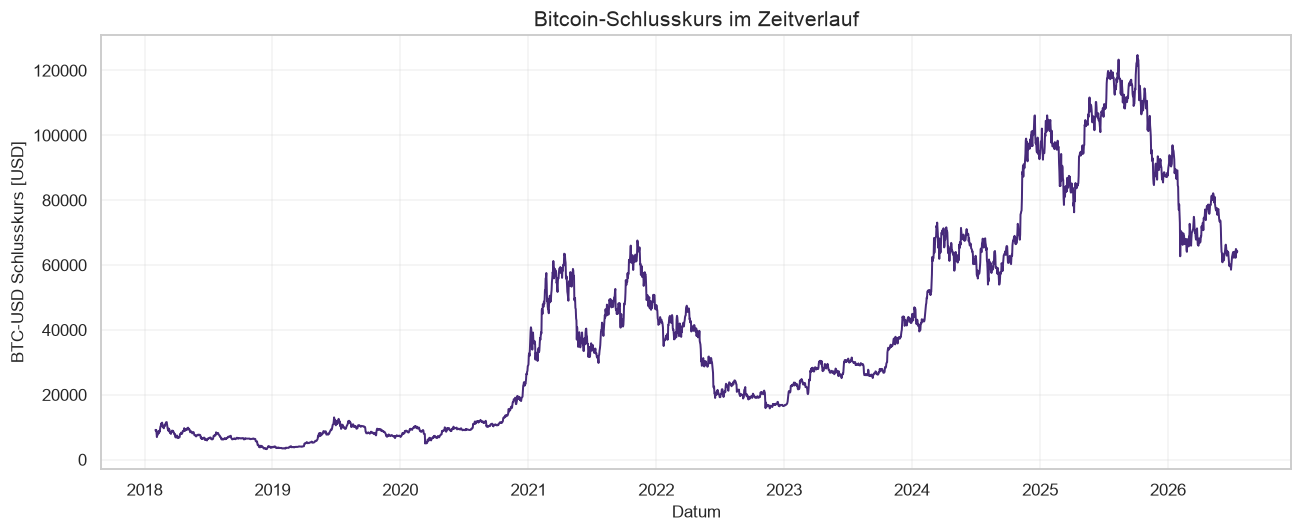

In [12]:
# Plot the price separately because its scale differs from returns
fig, ax = plt.subplots()
ax.plot(aligned.index, aligned["btc_close"], color=COLORS["btc"], linewidth=1.3)
ax.set_title("Bitcoin-Schlusskurs im Zeitverlauf")
ax.set_xlabel("Datum")
ax.set_ylabel("BTC-USD Schlusskurs [USD]")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

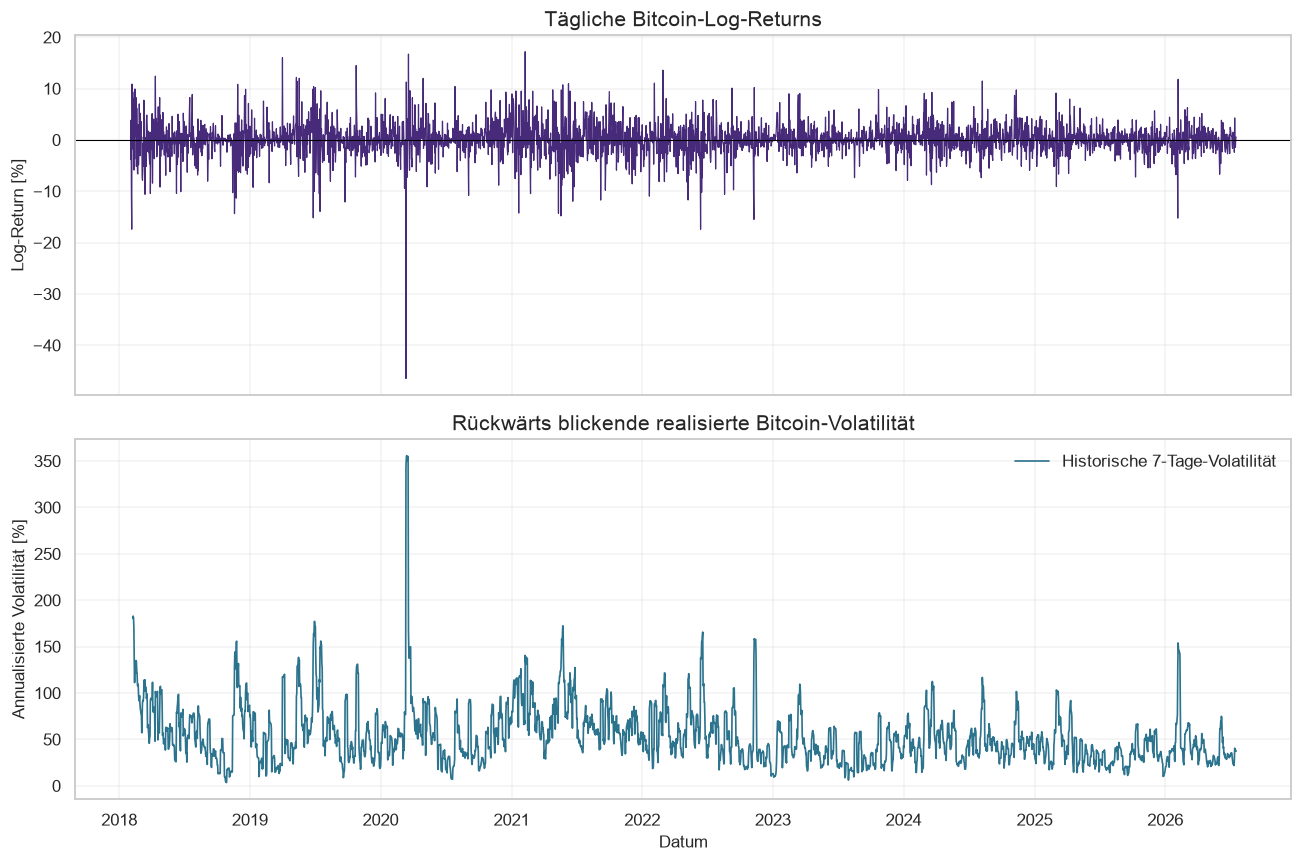

In [13]:
# Compare daily returns with backward-looking annualized volatility
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(
    aligned.index,
    aligned["btc_log_return"] * 100,
    color=COLORS["btc"],
    linewidth=0.8,
)
axes[0].axhline(0, color="black", linewidth=0.7)
axes[0].set_title("Tägliche Bitcoin-Log-Returns")
axes[0].set_ylabel("Log-Return [%]")
axes[0].grid(alpha=0.25)

axes[1].plot(
    aligned.index,
    aligned["rv_7_annualized"] * 100,
    color=COLORS["volatility"],
    linewidth=1.1,
    label="Historische 7-Tage-Volatilität",
)
axes[1].set_title("Rückwärts blickende realisierte Bitcoin-Volatilität")
axes[1].set_xlabel("Datum")
axes[1].set_ylabel("Annualisierte Volatilität [%]")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

In [14]:
# Quantify volatility clustering with autocorrelation of absolute returns
abs_return_autocorrelation = modeling_data["btc_abs_return"].autocorr(lag=1)
peak_volatility_date = aligned["rv_7_annualized"].idxmax()
peak_volatility = aligned.loc[peak_volatility_date, "rv_7_annualized"] * 100

display(
    Markdown(
        f'''
#### Interpretation

Wir erkennen deutlich wechselnde Volatilitätsregime. Die höchste rückwärts
blickende annualisierte 7-Tage-Volatilität liegt am
**{peak_volatility_date.date()}** bei **{peak_volatility:.1f}%**. Die
Lag-1-Autokorrelation der absoluten Returns beträgt
**{abs_return_autocorrelation:.2f}**. Ein positiver Wert unterstützt die
Annahme von Volatilitätsclustering und damit den späteren Vergleich mit GARCH.
'''
    )
)


#### Interpretation

Wir erkennen deutlich wechselnde Volatilitätsregime. Die höchste rückwärts
blickende annualisierte 7-Tage-Volatilität liegt am
**2020-03-14** bei **355.7%**. Die
Lag-1-Autokorrelation der absoluten Returns beträgt
**0.17**. Ein positiver Wert unterstützt die
Annahme von Volatilitätsclustering und damit den späteren Vergleich mit GARCH.


### 6.2 Verteilung der Zielvariable

#### Erklärung

Wir betrachten die Verteilung von \(\mathrm{RV}_{t,7}\), weil starke
Rechtsschiefe und Ausreisser die Modellwahl und den Unterschied zwischen MAE
und RMSE beeinflussen. RMSE gewichtet grosse Fehler stärker als MAE.

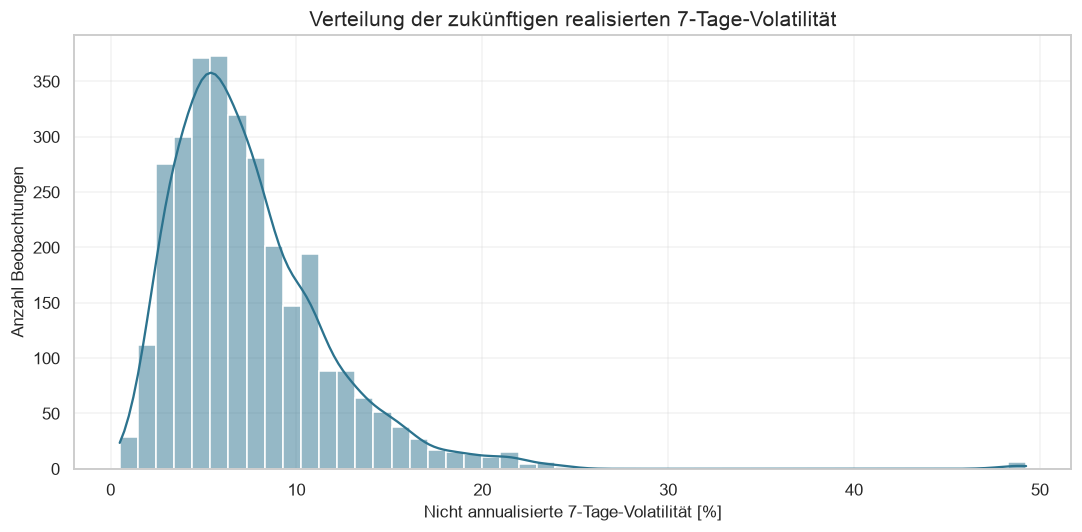

In [15]:
# Show the target distribution in percent without annualizing it
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(
    modeling_table["target_rv_7"] * 100,
    bins=50,
    kde=True,
    color=COLORS["volatility"],
    ax=ax,
)
ax.set_title("Verteilung der zukünftigen realisierten 7-Tage-Volatilität")
ax.set_xlabel("Nicht annualisierte 7-Tage-Volatilität [%]")
ax.set_ylabel("Anzahl Beobachtungen")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [16]:
# Compare the center and upper tail of the target distribution
target_quantiles = (
    modeling_table["target_rv_7"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99])
    .mul(100)
    .rename("7-Tage-Volatilität [%]")
    .to_frame()
)
display(target_quantiles.round(2))

distribution_skew = modeling_table["target_rv_7"].skew()
display(
    Markdown(
        f'''
#### Interpretation

Die Zielvariable ist mit einer Schiefe von **{distribution_skew:.2f}**
rechtsschief. Wir verwenden deshalb später sowohl MAE als robuste
Durchschnittsmetrik als auch RMSE, um besonders grosse Prognosefehler sichtbar
zu machen. Die Persistenz-Baseline bleibt wichtig, weil die Zielvariable
zeitlich geglättet und stark abhängig ist.
'''
    )
)

,7-Tage-Volatilität [%]
0.50,6.60
0.75,9.39
0.90,12.74
0.95,15.21
0.99,21.26



#### Interpretation

Die Zielvariable ist mit einer Schiefe von **2.67**
rechtsschief. Wir verwenden deshalb später sowohl MAE als robuste
Durchschnittsmetrik als auch RMSE, um besonders grosse Prognosefehler sichtbar
zu machen. Die Persistenz-Baseline bleibt wichtig, weil die Zielvariable
zeitlich geglättet und stark abhängig ist.


### 6.3 Externe Indikatoren und Bitcoin-Volatilität

#### Erklärung

Fear & Greed, VIX, DXY und Nasdaq haben unterschiedliche Einheiten. Für einen
rein visuellen Vergleich standardisieren wir die verzögerten Niveaus deshalb
mit einem Z-Score:

$$
z_t = \frac{x_t-\bar{x}}{s_x}
$$

Diese Standardisierung dient nur der EDA. Im späteren Backtesting darf eine
Skalierung ausschliesslich auf dem jeweiligen Trainingsfold geschätzt werden.

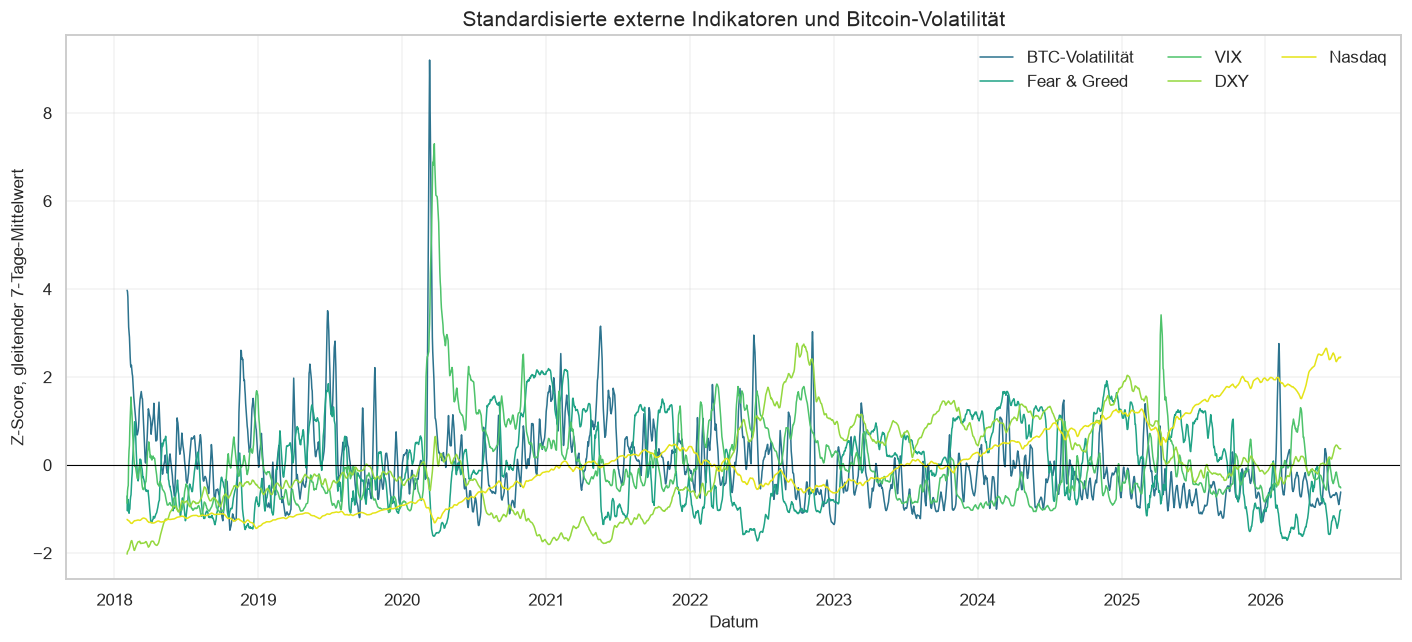

In [17]:
# Standardize levels only for this exploratory comparison
comparison_levels = aligned[
    [
        "target_rv_7_annualized",
        "fear_greed",
        "vix_close",
        "dxy_close",
        "nasdaq_close",
    ]
].dropna()
standardized_levels = (
    comparison_levels - comparison_levels.mean()
) / comparison_levels.std()

# Smooth visual noise without changing the modeling table
standardized_smoothed = standardized_levels.rolling(7, min_periods=1).mean()
display_names = {
    "target_rv_7_annualized": "BTC-Volatilität",
    "fear_greed": "Fear & Greed",
    "vix_close": "VIX",
    "dxy_close": "DXY",
    "nasdaq_close": "Nasdaq",
}
plot_colors = [
    COLORS["volatility"],
    COLORS["fear_greed"],
    COLORS["vix"],
    COLORS["dxy"],
    COLORS["nasdaq"],
]

fig, ax = plt.subplots(figsize=(13, 6))
for column, color in zip(standardized_smoothed.columns, plot_colors):
    ax.plot(
        standardized_smoothed.index,
        standardized_smoothed[column],
        label=display_names[column],
        color=color,
        linewidth=1.0,
    )
ax.axhline(0, color="black", linewidth=0.7)
ax.set_title("Standardisierte externe Indikatoren und Bitcoin-Volatilität")
ax.set_xlabel("Datum")
ax.set_ylabel("Z-Score, gleitender 7-Tage-Mittelwert")
ax.legend(ncol=3)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### 6.4 Korrelationen mit der Zielvariable

#### Erklärung

Wir messen lineare Zusammenhänge mit der Pearson-Korrelation. Eine Korrelation
beweist keine Kausalität und kann sich zwischen Marktregimen verändern. Sie
hilft uns aber, redundante Features und erste Kandidaten für XGBoost zu
erkennen.

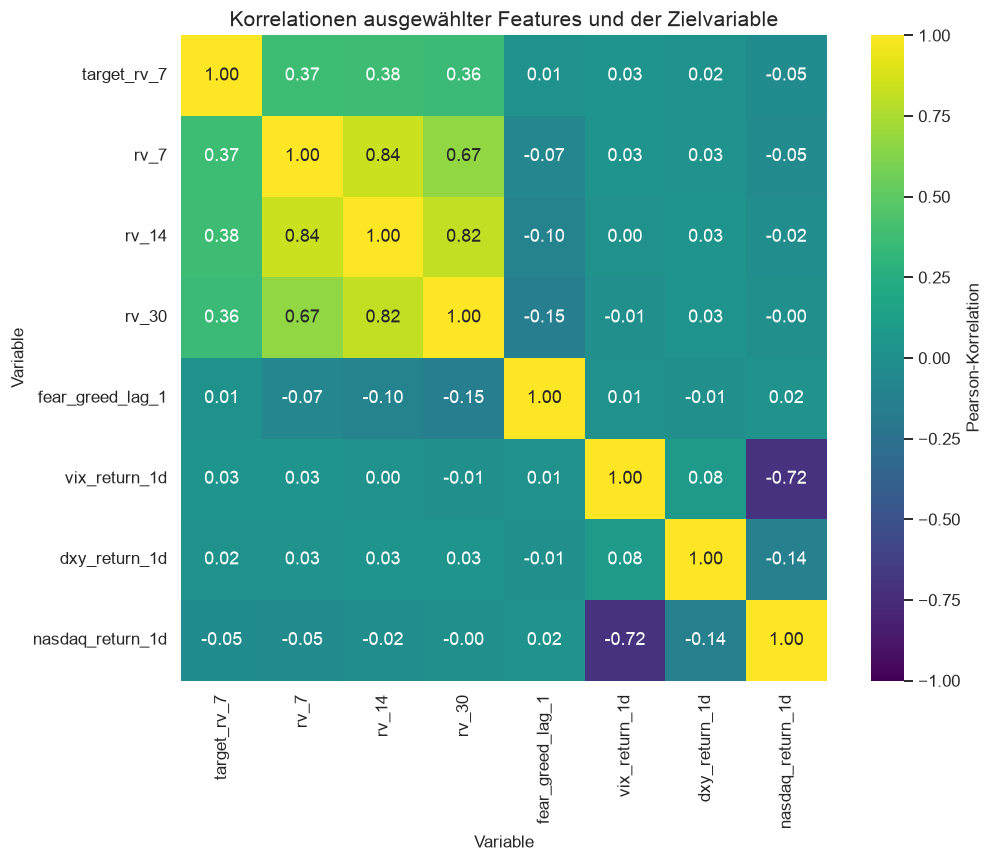

In [18]:
# Keep the heatmap compact and focused on interpretable feature groups
correlation_columns = [
    "target_rv_7",
    "rv_7",
    "rv_14",
    "rv_30",
    "fear_greed_lag_1",
    "vix_return_1d",
    "dxy_return_1d",
    "nasdaq_return_1d",
]
correlation_matrix = modeling_table[correlation_columns].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    cmap="viridis",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"label": "Pearson-Korrelation"},
    ax=ax,
)
ax.set_title("Korrelationen ausgewählter Features und der Zielvariable")
ax.set_xlabel("Variable")
ax.set_ylabel("Variable")
fig.tight_layout()
plt.show()

In [19]:
# Rank absolute correlations with the future volatility target
target_correlations = (
    correlation_matrix["target_rv_7"]
    .drop("target_rv_7")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
correlation_ranking = target_correlations.rename("Korrelation mit target_rv_7").to_frame()
display(correlation_ranking.round(3))

strongest_feature = target_correlations.index[0]
strongest_correlation = target_correlations.iloc[0]
display(
    Markdown(
        f'''
#### Interpretation

Unter den dargestellten Merkmalen weist **`{strongest_feature}`** mit
**{strongest_correlation:.2f}** den stärksten linearen Zusammenhang zur
zukünftigen 7-Tage-Volatilität auf. Wir erwarten, dass historische
Volatilitätsmerkmale wegen des Volatilitätsclusterings stärker korrelieren als
einzelne tägliche externe Returns. Ob Fear & Greed, VIX, DXY und Nasdaq
zusätzlichen Prognosewert liefern, prüfen wir später ausschliesslich mit
Walk-forward Backtesting.
'''
    )
)

,Korrelation mit target_rv_7
rv_14,0.377
rv_7,0.370
rv_30,0.359
nasdaq_return_1d,-0.046
vix_return_1d,0.035
dxy_return_1d,0.016
fear_greed_lag_1,0.011



#### Interpretation

Unter den dargestellten Merkmalen weist **`rv_14`** mit
**0.38** den stärksten linearen Zusammenhang zur
zukünftigen 7-Tage-Volatilität auf. Wir erwarten, dass historische
Volatilitätsmerkmale wegen des Volatilitätsclusterings stärker korrelieren als
einzelne tägliche externe Returns. Ob Fear & Greed, VIX, DXY und Nasdaq
zusätzlichen Prognosewert liefern, prüfen wir später ausschliesslich mit
Walk-forward Backtesting.


## 7. Zwischenfazit und nächste Schritte

### Erklärung

Wir haben nun eine leakage-bewusste, tägliche Modelling-Tabelle und erste
Hinweise auf Volatilitätsclustering. Die EDA allein beantwortet die
Forschungsfrage noch nicht.

### Code und Ergebnis

Die Datei `data/processed/bitcoin_volatility_modeling_table.csv` wurde im
Feature-Abschnitt reproduzierbar erzeugt. Sie bleibt lokal und wird nicht auf
GitHub versioniert, weil alle Quelldaten im Notebook erneut geladen werden
können.

### Interpretation

Als nächsten Teil ergänzen wir:

1. expanding-window Walk-forward Folds,
2. MAE und RMSE,
3. naive Persistenz und gleitende Mittelwerte,
4. GARCH,
5. XGBoost mit den festgelegten Feature-Sets,
6. Chronos-2 als moderne Vergleichsmethode.

Lightning verwenden wir nicht, solange kein eigenes PyTorch-Modell trainiert
wird. Für Zero-Shot-Inferenz mit Chronos-2 genügt die direkte Modell-API.